In [104]:
# Carga de librerías
from datetime import datetime
from dotenv import load_dotenv
from fredapi import Fred
import glob
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import os
import yfinance as yf


# Obtención de datos

In [20]:
# Precios históricos de Ethereum, variables macroeconomicas, indices financieros
df_raw =  yf.download(
        ["ETH-USD", # Ethereum
        "^GSPC", # SP500
        "BTC-USD", # Bitcoin
        "^NDX", # Nasdaq
        "^VIX", # Indice de volatilidad
        "DX-Y.NYB",  # Indice del dolar
        "GC=F", # Precio del oro
        "SI=F", # Precio de la plata
        "CL=F" # Precio del petroleo
        ], 
        start="2022-02-01",
        end="2026-09-30",
        interval="1d"
)

# Selección de precios por activo 
df_raw.columns = [price + "_" +  ticker for price, ticker in df_raw.columns]
df_raw = df_raw.loc[:, df_raw.columns.str.contains("ETH-USD") | df_raw.columns.str.startswith("Close_"),]

df_raw.head()


[*********************100%***********************]  8 of 9 completed


,Close_BTC-USD,Close_CL=F,Close_DX-Y.NYB,Close_ETH-USD,Close_GC=F,Close_SI=F,Close_^GSPC,Close_^NDX,Close_^VIX,High_ETH-USD,Low_ETH-USD,Open_ETH-USD,Volume_ETH-USD
Date,,,,,,,,,,,,,
2022-02-01,38743.273438,88.199997,96.389999,2792.117188,1801.500000,22.596001,4546.540039,15019.679688,21.959999,2802.315430,2682.621826,2687.898926,13194846235
2022-02-02,36952.984375,88.260002,95.940002,2682.854004,1810.300049,22.711000,4589.379883,15139.740234,22.090000,2802.212158,2630.120361,2791.958984,13876301217
2022-02-03,37154.601562,90.269997,95.379997,2679.162598,1804.099976,22.375000,4477.439941,14501.110352,24.350000,2712.482666,2587.783447,2682.226074,12755505065
2022-02-04,41500.875000,92.309998,95.480003,2983.586914,1807.800049,22.475000,4500.529785,14694.349609,23.219999,2983.586914,2675.443848,2681.057617,18987223729
2022-02-05,41441.164062,NaN,NaN,3014.648193,NaN,NaN,NaN,NaN,NaN,3054.130127,2966.781006,2984.446045,13102093957


In [ ]:
# Métricas On-Chain para Ethereum

START_DATE = datetime(2022, 2, 1)
END_DATE = datetime(2026, 9, 30)

# Valor Total Bloqueado
url_tvl = "https://api.llama.fi/v2/historicalChainTvl/Ethereum"
data_tvl = requests.get(url_tvl, timeout=15)
data_tvl.raise_for_status()

tvl = pd.DataFrame(data_tvl.json())
tvl["date"] = pd.to_datetime(tvl["date"], unit="s")
tvl = tvl.rename(columns={"tvl": "tvl_usd"})
tvl = tvl[["date", "tvl_usd"]]

# Volumen diario DEX
url_volume = "https://api.llama.fi/overview/dexs/Ethereum?excludeTotalDataChart=false&excludeTotalDataChartBreakdown=true"
data_volume = requests.get(url_volume, timeout=15)
data_volume.raise_for_status()
data_volume = data_volume.json()

volume = pd.DataFrame(
    data_volume["totalDataChart"],
    columns=["timestamp", "daily_volume_usd"]
)
volume["date"] = pd.to_datetime(volume["timestamp"], unit="s")
volume = volume[["date", "daily_volume_usd"]]

# Comisiones diarias
url_fees = "https://api.llama.fi/overview/fees/Ethereum?excludeTotalDataChart=false&excludeTotalDataChartBreakdown=true"
data_fees = requests.get(url_fees, timeout=15)
data_fees.raise_for_status()
data_fees = data_fees.json()

fees = pd.DataFrame(
    data_fees["totalDataChart"],
    columns=["timestamp", "daily_fees_usd"]
)
fees["date"] = pd.to_datetime(fees["timestamp"], unit="s")
fees = fees[["date", "daily_fees_usd"]]

# Capitalización total de stablecoins asociadas a Ethereum
url = "https://stablecoins.llama.fi/stablecoincharts/Ethereum"

data_stablecoins = requests.get(url, timeout=30)
data_stablecoins.raise_for_status()
data_stablecoins = data_stablecoins.json()

stablecoins = pd.DataFrame(data_stablecoins)

stablecoins["date"] = pd.to_datetime(
    pd.to_numeric(stablecoins["date"], errors="coerce"),
    unit="s",
    errors="coerce",
    utc=True
).dt.tz_localize(None)

stablecoins["stablecoin_mcap_usd"] = stablecoins[
    "totalCirculatingUSD"
].apply(lambda x: x.get("peggedUSD") if isinstance(x, dict) else None)

stablecoins = stablecoins[["date", "stablecoin_mcap_usd"]]

# Unificación de métricas
metricas = {
    "TVL": tvl,
    "Volumen DEX": volume,
    "Comisiones": fees,
    "Cap_StableCoins": stablecoins
}

for metrica, df in metricas.items():
    df["date"] = pd.to_datetime(df["date"]).dt.normalize()
    df.dropna(subset=["date"], inplace=True)
    df.drop_duplicates(subset=["date"], keep="last", inplace=True)

    metricas[metrica] = df[
        (df["date"] >= pd.Timestamp(START_DATE))
        &
        (df["date"] < pd.Timestamp(END_DATE) + pd.Timedelta(days=1))
    ].copy()

df_chain = pd.concat(
    [df.set_index("date") for df in metricas.values()],
    axis=1,
    join="outer"
)

df_chain.head()


,tvl_usd,daily_volume_usd,daily_fees_usd,stablecoin_mcap_usd
date,,,,
2022-02-01,70970297086,2.214025e+09,39698470.0,9.555990e+10
2022-02-02,72448166781,2.108429e+09,38023308.0,9.592614e+10
2022-02-03,70791608799,1.936073e+09,36135548.0,9.649806e+10
2022-02-04,71190935209,2.283265e+09,34331060.0,9.713747e+10
2022-02-05,75763275881,1.959551e+09,30444359.0,9.831297e+10


In [39]:
# Variables macro adicionales

# directorio_trabajo  =  r"C:\Users\reyes\Downloads\Proyecto_MIAD\Datos\.env"
# load_dotenv(dotenv_path=directorio_trabajo, override =  True)
# fred_key  =  os.environ.get("FRED_KEY")

# fred =  Fred(api_key  =  fred_key)

# series_fred = {
#     "DGS2": "yield_2y",              # Rendimiento del Tesoro a 2 años
#     "DGS10": "yield_10y",            # Rendimiento del Tesoro a 10 años
#     "DFF": "fed_funds_rate",         # Tasa efectiva de fondos federales
#     "RRPONTSYD": "fed_reverse_repo", # Operaciones repo inversas de la Fed
#     "BAMLH0A0HYM2": "high_yield_spread" # Diferencial de bonos high yield
# }

# datos_dict =  {}

# for nombre, indicador in series_fred.items():
#     datos_dict[indicador] = fred.get_series(
#         nombre, 
#         observation_start="2022-02-01", 
#         observation_end="2026-09-30"
#     )

# df_macro  =  (
#     pd.DataFrame(datos_dict)

# )
# df_macro.head(1)

In [41]:
# Carga noticias Ethereum
ubicacion =  glob.glob("C:/Users/reyes/Downloads/Proyecto_MIAD/Datos/*.csv")
lista_df =  [pd.read_csv(bloque) for bloque in ubicacion]
df_noticias  =  pd.concat(lista_df, ignore_index =  True)
df_noticias.head(1)

,fecha,titulo,resumen,relevancia_eth,sentimiento_eth,sentimiento_general
0,18/03/2022 18:06,Here's Why This Rare CryptoPunk NFT Just Sold ...,"CryptoPunks are a generative art collection, a...",0.495963,0.008528,0.068026


In [77]:
# Obtención de busquedas de Ethereum en Google 
# Adaptado  de https://github.com/GeneralMills/pytrends/blob/master/pytrends/dailydata.py

from datetime import date, timedelta
from functools import partial
from time import sleep
from calendar import monthrange

import pandas as pd

from pytrends.exceptions import ResponseError
from pytrends.request import TrendReq


def get_last_date_of_month(year: int, month: int) -> date:
    """Given a year and a month returns an instance of the date class
    containing the last day of the corresponding month.

    Source: https://stackoverflow.com/questions/42950/get-last-day-of-the-month-in-python
    """
    return date(year, month, monthrange(year, month)[1])


def convert_dates_to_timeframe(start: date, stop: date) -> str:
    """Given two dates, returns a stringified version of the interval between
    the two dates which is used to retrieve data for a specific time frame
    from Google Trends.
    """
    return f"{start.strftime('%Y-%m-%d')} {stop.strftime('%Y-%m-%d')}"


def _normalize_index(data: pd.DataFrame) -> pd.DataFrame:
    """Normaliza el índice de fechas devuelto por Google Trends."""
    data = data.copy()

    index = pd.to_datetime(data.index)

    # Elimina timezone si Google Trends devuelve fechas con timezone.
    if getattr(index, "tz", None) is not None:
        index = index.tz_localize(None)

    data.index = index.normalize()
    data = data[~data.index.duplicated(keep="last")]
    data = data.sort_index()

    return data


def _fetch_data(pytrends, build_payload, timeframe: str) -> pd.DataFrame:
    """Attempts to fecth data and retries in case of a ResponseError."""
    attempts, fetched = 0, False

    while not fetched:
        try:
            build_payload(timeframe=timeframe)
        except ResponseError as err:
            print(err)
            print(f'Trying again in {60 + 5 * attempts} seconds.')
            sleep(60 + 5 * attempts)
            attempts += 1

            if attempts > 3:
                print('Failed after 3 attemps, abort fetching.')
                break
        else:
            fetched = True

    data = pytrends.interest_over_time()

    if data is None or data.empty:
        raise RuntimeError(
            f'Google Trends returned no data for timeframe: {timeframe}'
        )

    return _normalize_index(data)


def get_daily_data(word: str,
                   start_year: int,
                   start_mon: int,
                   stop_year: int,
                   stop_mon: int,
                   geo: str = '',
                   verbose: bool = True,
                   wait_time: float = 5.0) -> pd.DataFrame:
    """Given a word, fetches daily search volume data from Google Trends and
    returns results in a pandas DataFrame.

    Details: Due to the way Google Trends scales and returns data, special
    care needs to be taken to make the daily data comparable over different
    months. To do that, we download daily data on a month by month basis,
    and also monthly data. The monthly data is downloaded in one go, so that
    the monthly values are comparable amongst themselves and can be used to
    scale the daily data. The daily data is scaled by multiplying the daily
    value by the monthly search volume divided by 100.
    For a more detailed explanation see http://bit.ly/trendsscaling

    Args:
        word (str): Word to fetch daily data for.
        start_year (int): the start year
        start_mon (int): start 1st day of the month
        stop_year (int): the end year
        stop_mon (int): end at the last day of the month
        geo (str): geolocation
        verbose (bool): If True, then prints the word and current time frame
            we are fecthing the data for.

    Returns:
        complete (pd.DataFrame): Contains 4 columns.
            The column named after the word argument contains the daily search
            volume already scaled and comparable through time.
            The column f'{word}_unscaled' is the original daily data fetched
            month by month, and it is not comparable across different months
            (but is comparable within a month).
            The column f'{word}_monthly' contains the original monthly data
            fetched at once. The values in this column have been backfilled
            so that there are no NaN present.
            The column 'scale' contains the scale used to obtain the scaled
            daily data.
    """

    # Set up start and stop dates
    start_date = date(start_year, start_mon, 1)
    stop_date = get_last_date_of_month(stop_year, stop_mon)

    # Start pytrends for US region
    # geo='' means worldwide data.
    pytrends = TrendReq(hl='en-US', tz=360)

    # Initialize build_payload with the word we need data for
    build_payload = partial(pytrends.build_payload,
                            kw_list=[word], cat=0, geo=geo, gprop='')

    # Obtain monthly data for all months in years [start_year, stop_year]
    monthly = _fetch_data(
        pytrends,
        build_payload,
        convert_dates_to_timeframe(start_date, stop_date)
    )

    # Normalize monthly data and convert it to calendar months.
    #
    # For long timeframes Google Trends may return weekly or monthly data.
    # Resampling ensures that the index is always aligned to the first day
    # of each calendar month.
    monthly = monthly[[word]].resample('MS').mean()

    # Get daily data, month by month
    results = {}

    # if a timeout or too many requests error occur we need to adjust wait time
    current = start_date

    while current <= stop_date:
        last_date_of_month = get_last_date_of_month(
            current.year,
            current.month
        )

        # Avoid going beyond the requested final date.
        last_date_of_month = min(last_date_of_month, stop_date)

        timeframe = convert_dates_to_timeframe(
            current,
            last_date_of_month
        )

        if verbose:
            print(f'{word}:{timeframe}')

        daily_data = _fetch_data(
            pytrends,
            build_payload,
            timeframe
        )

        daily_data = daily_data.drop(
            columns=['isPartial'],
            errors='ignore'
        )

        if word not in daily_data.columns:
            raise RuntimeError(
                f'Column {word!r} was not returned for {timeframe}.'
            )

        results[current] = daily_data[[word]]

        current = last_date_of_month + timedelta(days=1)
        sleep(wait_time)  # don't go too fast or Google will send 429s

    daily = pd.concat(results.values())

    # Normalize the daily index and remove possible duplicated dates.
    daily = _normalize_index(daily)

    # Keep only the requested date range.
    daily = daily.loc[
        (daily.index >= pd.Timestamp(start_date)) &
        (daily.index <= pd.Timestamp(stop_date))
    ]

    daily = daily.rename(columns={word: f'{word}_unscaled'})

    month_index = daily.index.to_period('M').to_timestamp()

    daily[f'{word}_monthly'] = (
        monthly[word]
        .reindex(month_index)
        .to_numpy()
    )

    # Fill missing monthly values if Google Trends omitted any month.
    daily[f'{word}_monthly'] = (
        daily[f'{word}_monthly']
        .ffill()
        .bfill()
    )

    # Scale daily data by monthly weights so the data is comparable
    daily['scale'] = daily[f'{word}_monthly'] / 100

    daily[word] = (
        daily[f'{word}_unscaled'] * daily['scale']
    )

    complete = daily[
        [
            word,
            f'{word}_unscaled',
            f'{word}_monthly',
            'scale'
        ]
    ]

    return complete


df_trends  =  get_daily_data(
    word='Ethereum',
    start_year=2022,
    start_mon=2,
    stop_year=2026,
    stop_mon=9,
    geo='',          # Mundial
    verbose=True,
    wait_time=8
)
df_trends

Ethereum:2022-02-01 2022-02-28
Ethereum:2022-03-01 2022-03-31
Ethereum:2022-04-01 2022-04-30
Ethereum:2022-05-01 2022-05-31
Ethereum:2022-06-01 2022-06-30
Ethereum:2022-07-01 2022-07-31
Ethereum:2022-08-01 2022-08-31
Ethereum:2022-09-01 2022-09-30
Ethereum:2022-10-01 2022-10-31
Ethereum:2022-11-01 2022-11-30
Ethereum:2022-12-01 2022-12-31
Ethereum:2023-01-01 2023-01-31
Ethereum:2023-02-01 2023-02-28
Ethereum:2023-03-01 2023-03-31
Ethereum:2023-04-01 2023-04-30
Ethereum:2023-05-01 2023-05-31
Ethereum:2023-06-01 2023-06-30
Ethereum:2023-07-01 2023-07-31
Ethereum:2023-08-01 2023-08-31
Ethereum:2023-09-01 2023-09-30
Ethereum:2023-10-01 2023-10-31
Ethereum:2023-11-01 2023-11-30
Ethereum:2023-12-01 2023-12-31
Ethereum:2024-01-01 2024-01-31
Ethereum:2024-02-01 2024-02-29
Ethereum:2024-03-01 2024-03-31
Ethereum:2024-04-01 2024-04-30
Ethereum:2024-05-01 2024-05-31
Ethereum:2024-06-01 2024-06-30
Ethereum:2024-07-01 2024-07-31
Ethereum:2024-08-01 2024-08-31
Ethereum:2024-09-01 2024-09-30
Ethereum

,Ethereum,Ethereum_unscaled,Ethereum_monthly,scale
date,,,,
2022-02-01,27.0575,79,34.25,0.3425
2022-02-02,25.6875,75,34.25,0.3425
2022-02-03,24.6600,72,34.25,0.3425
2022-02-04,30.1400,88,34.25,0.3425
2022-02-05,28.4275,83,34.25,0.3425
...,...,...,...,...
2026-09-26,4.5725,31,14.75,0.1475
2026-09-27,4.7200,32,14.75,0.1475
2026-09-28,5.6050,38,14.75,0.1475


In [79]:
df_trends.to_csv("C:/Users/reyes/Downloads/Proyecto_MIAD/busquedas_google_trends.csv")

# Preprocesamiento de datos

In [57]:
# Preprocesamiento precios históricos
print("Valores faltantes precios históricos: ", df_raw.isnull().sum().sum())
print("Valores duplicados precios históricos:", df_raw.duplicated().sum())
print("Estructura del DataFrame de precios históricos:\n")
df_raw.info()

Valores faltantes precios históricos:  3720
Valores duplicados precios históricos: 0
Estructura del DataFrame de precios históricos:

<class 'pandas.DataFrame'>
DatetimeIndex: 1702 entries, 2022-02-01 to 2026-09-29
Freq: D
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Close_BTC-USD   1702 non-null   float64
 1   Close_CL=F      1171 non-null   float64
 2   Close_DX-Y.NYB  1171 non-null   float64
 3   Close_ETH-USD   1702 non-null   float64
 4   Close_GC=F      1172 non-null   float64
 5   Close_SI=F      1171 non-null   float64
 6   Close_^GSPC     1169 non-null   float64
 7   Close_^NDX      1169 non-null   float64
 8   Close_^VIX      1171 non-null   float64
 9   High_ETH-USD    1702 non-null   float64
 10  Low_ETH-USD     1702 non-null   float64
 11  Open_ETH-USD    1702 non-null   float64
 12  Volume_ETH-USD  1702 non-null   int64  
dtypes: float64(12), int64(1)
memory usage: 186.2 KB


In [58]:
# Imputación de valores faltantes con fffill
df_precios  =  df_raw.ffill()
print("Valores faltantes precios históricos: ", df_precios.isnull().sum().sum())
print("Valores duplicados precios históricos:", df_precios.duplicated().sum())
df_precios.head()

Valores faltantes precios históricos:  0
Valores duplicados precios históricos: 0


,Close_BTC-USD,Close_CL=F,Close_DX-Y.NYB,Close_ETH-USD,Close_GC=F,Close_SI=F,Close_^GSPC,Close_^NDX,Close_^VIX,High_ETH-USD,Low_ETH-USD,Open_ETH-USD,Volume_ETH-USD
Date,,,,,,,,,,,,,
2022-02-01,38743.273438,88.199997,96.389999,2792.117188,1801.500000,22.596001,4546.540039,15019.679688,21.959999,2802.315430,2682.621826,2687.898926,13194846235
2022-02-02,36952.984375,88.260002,95.940002,2682.854004,1810.300049,22.711000,4589.379883,15139.740234,22.090000,2802.212158,2630.120361,2791.958984,13876301217
2022-02-03,37154.601562,90.269997,95.379997,2679.162598,1804.099976,22.375000,4477.439941,14501.110352,24.350000,2712.482666,2587.783447,2682.226074,12755505065
2022-02-04,41500.875000,92.309998,95.480003,2983.586914,1807.800049,22.475000,4500.529785,14694.349609,23.219999,2983.586914,2675.443848,2681.057617,18987223729
2022-02-05,41441.164062,92.309998,95.480003,3014.648193,1807.800049,22.475000,4500.529785,14694.349609,23.219999,3054.130127,2966.781006,2984.446045,13102093957


In [60]:
# Preprocesamiento métricas on chain
print("Valores faltantes métricas on-chain: ", df_chain.isnull().sum().sum())
print("Valores duplicados métricas on-chain:", df_chain.duplicated().sum())
print("Estructura del DataFrame de métricas on-chain:\n")
df_chain.info()

Valores faltantes métricas on-chain:  0
Valores duplicados métricas on-chain: 0
Estructura del DataFrame de métricas on-chain:

<class 'pandas.DataFrame'>
DatetimeIndex: 1703 entries, 2022-02-01 to 2026-09-30
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   tvl_usd              1703 non-null   int64  
 1   daily_volume_usd     1703 non-null   float64
 2   daily_fees_usd       1703 non-null   float64
 3   stablecoin_mcap_usd  1703 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 66.5 KB


In [61]:
df_chain.head()

,tvl_usd,daily_volume_usd,daily_fees_usd,stablecoin_mcap_usd
date,,,,
2022-02-01,70970297086,2.214025e+09,39698470.0,9.555990e+10
2022-02-02,72448166781,2.108429e+09,38023308.0,9.592614e+10
2022-02-03,70791608799,1.936073e+09,36135548.0,9.649806e+10
2022-02-04,71190935209,2.283265e+09,34331060.0,9.713747e+10
2022-02-05,75763275881,1.959551e+09,30444359.0,9.831297e+10


In [63]:
# Preprocesamiento noticias de Ethereum
print("Valores faltantes noticias financieras: ", df_noticias.isnull().sum().sum())
print("Valores duplicados noticias financieras:", df_noticias.duplicated().sum())
print("Estructura del DataFrame noticias financieras:\n")
df_noticias.info()

Valores faltantes noticias financieras:  8
Valores duplicados noticias financieras: 103
Estructura del DataFrame noticias financieras:

<class 'pandas.DataFrame'>
RangeIndex: 15452 entries, 0 to 15451
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   fecha                15451 non-null  str    
 1   titulo               15451 non-null  str    
 2   resumen              15449 non-null  str    
 3   relevancia_eth       15451 non-null  float64
 4   sentimiento_eth      15451 non-null  float64
 5   sentimiento_general  15451 non-null  float64
dtypes: float64(3), str(3)
memory usage: 724.4 KB


In [65]:
# Eliminación de duplicados, imputación de valores faltantes y calculo de sentimiento promedio diario

df_noticias =  df_noticias.drop_duplicates()
df_noticias.ffill(inplace  =  True)
df_noticias["fecha"] =  pd.to_datetime(df_noticias["fecha"], format =  "%d/%m/%Y %H:%M", errors =  "coerce")
df_sentimiento_diario  =  (
    df_noticias.groupby(df_noticias["fecha"].dt.date)["sentimiento_eth"]
    .mean()
    .reset_index()
    .rename(columns  =  {"sentimiento_eth": "avg_sentimiento_eth"})
)
df_sentimiento_diario.set_index("fecha", inplace  =  True)
df_sentimiento_diario.index = pd.to_datetime(df_sentimiento_diario.index, format  =  "%Y-%m-%d", errors  =  "coerce")
df_sentimiento_diario.head()


,avg_sentimiento_eth
fecha,
2022-03-18,0.010343
2022-03-19,-0.013255
2022-03-20,0.007418
2022-03-21,-0.012968
2022-03-22,0.008810


In [68]:
print("Valores faltantes noticias financieras: ", df_sentimiento_diario.isnull().sum().sum())
print("Valores duplicados noticias financieras:", df_sentimiento_diario.duplicated().sum())

Valores faltantes noticias financieras:  0
Valores duplicados noticias financieras: 0


In [80]:
# Preprocesamiento búsquedas internet 
print("Valores faltantes Google Trends: ", df_trends.isnull().sum().sum())
print("Estructura del DataFrame busquedas Google Trends:\n")
df_trends.info()

Valores faltantes Google Trends:  0
Estructura del DataFrame busquedas Google Trends:

<class 'pandas.DataFrame'>
DatetimeIndex: 1703 entries, 2022-02-01 to 2026-09-30
Freq: D
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Ethereum           1703 non-null   float64
 1   Ethereum_unscaled  1703 non-null   int64  
 2   Ethereum_monthly   1703 non-null   float64
 3   scale              1703 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 66.5 KB


In [82]:
df_busquedas =  df_trends[["Ethereum"]]
df_busquedas.columns = ["busquedas_ETH"]
df_busquedas.head()

,busquedas_ETH
date,
2022-02-01,27.0575
2022-02-02,25.6875
2022-02-03,24.6600
2022-02-04,30.1400
2022-02-05,28.4275


In [ ]:
# Obtención de conjunto de datos unificado
df = pd.concat([df_precios, df_chain, df_sentimiento_diario, df_busquedas], axis  =  1)
df_m =  df.copy()
df_m = df_m["2022-03-18":"2026-09-28"]
df_m

,Close_BTC-USD,Close_CL=F,Close_DX-Y.NYB,Close_ETH-USD,Close_GC=F,Close_SI=F,Close_^GSPC,Close_^NDX,Close_^VIX,High_ETH-USD,Low_ETH-USD,Open_ETH-USD,Volume_ETH-USD,tvl_usd,daily_volume_usd,daily_fees_usd,stablecoin_mcap_usd,avg_sentimiento_eth,busquedas_ETH
2022-03-18,41801.156250,104.699997,98.230003,2945.343018,1929.300049,25.055000,4463.120117,14420.080078,23.870001,2973.616211,2774.855713,2814.434570,1.583088e+10,71903421064,2.683794e+09,21478002.00,1.000697e+11,0.010343,18.0375
2022-03-19,42190.652344,104.699997,98.230003,2946.257080,1929.300049,25.055000,4463.120117,14420.080078,23.870001,2979.987061,2910.802246,2944.721680,1.157646e+10,73764840403,1.611898e+09,18237389.00,1.003356e+11,-0.013255,18.3150
2022-03-20,41247.824219,104.699997,98.230003,2860.459229,1929.300049,25.055000,4463.120117,14420.080078,23.870001,2956.965576,2826.107422,2946.547607,1.268473e+10,73918423609,1.584823e+09,16808525.00,1.003046e+11,0.007418,16.6500
2022-03-21,41077.996094,112.120003,98.500000,2897.976562,1929.500000,25.282000,4461.180176,14376.089844,23.530001,2954.556641,2838.250488,2860.103271,1.520612e+10,72705286022,1.662212e+09,14547401.00,1.002744e+11,-0.012968,16.6500
2022-03-22,42358.808594,111.760002,98.489998,2973.131104,1921.500000,24.885000,4511.609863,14654.330078,22.940001,3040.382812,2892.544434,2897.774170,1.683054e+10,75149457353,1.986793e+09,15322373.00,1.000954e+11,0.008810,20.5350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,84379.062500,94.610001,101.290001,2687.301514,4298.000000,63.457001,7704.129883,30478.859375,15.670000,2703.662842,2628.689209,2684.439453,1.403644e+10,53476048132,1.560725e+09,18303688.34,1.457870e+11,0.065478,4.7200
2026-09-25,84034.921875,92.410004,100.970001,2690.475586,4321.200195,64.245003,7743.410156,30608.130859,14.870000,2741.296875,2667.045166,2687.322510,1.323699e+10,53471256843,1.346021e+09,11634532.62,1.456898e+11,-0.183114,4.8675
2026-09-26,84406.453125,92.410004,100.970001,2695.213135,4321.200195,64.245003,7743.410156,30608.130859,14.870000,2696.996094,2665.862549,2690.481689,5.046145e+09,53426913771,9.332155e+08,10467434.69,1.455995e+11,NaN,4.5725
2026-09-27,84458.085938,92.410004,100.970001,2686.926758,4321.200195,64.245003,7743.410156,30608.130859,14.870000,2722.039307,2669.472656,2695.348877,8.065976e+09,53418198239,8.811220e+08,10733516.16,1.459715e+11,0.180779,4.7200


In [92]:
print("Valores faltantes conjunto unificado: ", df_m.isnull().sum().sum())
print("Valores duplicados conjunto unificado:", df_m.duplicated().sum())
print("Estructura del DataFrame unificado:\n")


Valores faltantes conjunto unificado:  303
Valores duplicados conjunto unificado: 0
Estructura del DataFrame unificado:



In [93]:
df_m["avg_sentimiento_eth"] =  df_m["avg_sentimiento_eth"].ffill()

In [318]:
df_m

,Close_BTC-USD,Close_CL=F,Close_DX-Y.NYB,Close_ETH-USD,Close_GC=F,Close_SI=F,Close_^GSPC,Close_^NDX,Close_^VIX,High_ETH-USD,Low_ETH-USD,Open_ETH-USD,Volume_ETH-USD,tvl_usd,daily_volume_usd,daily_fees_usd,stablecoin_mcap_usd,avg_sentimiento_eth,busquedas_ETH
2022-03-18,41801.156250,104.699997,98.230003,2945.343018,1929.300049,25.055000,4463.120117,14420.080078,23.870001,2973.616211,2774.855713,2814.434570,1.583088e+10,71903421064,2.683794e+09,21478002.00,1.000697e+11,0.010343,18.0375
2022-03-19,42190.652344,104.699997,98.230003,2946.257080,1929.300049,25.055000,4463.120117,14420.080078,23.870001,2979.987061,2910.802246,2944.721680,1.157646e+10,73764840403,1.611898e+09,18237389.00,1.003356e+11,-0.013255,18.3150
2022-03-20,41247.824219,104.699997,98.230003,2860.459229,1929.300049,25.055000,4463.120117,14420.080078,23.870001,2956.965576,2826.107422,2946.547607,1.268473e+10,73918423609,1.584823e+09,16808525.00,1.003046e+11,0.007418,16.6500
2022-03-21,41077.996094,112.120003,98.500000,2897.976562,1929.500000,25.282000,4461.180176,14376.089844,23.530001,2954.556641,2838.250488,2860.103271,1.520612e+10,72705286022,1.662212e+09,14547401.00,1.002744e+11,-0.012968,16.6500
2022-03-22,42358.808594,111.760002,98.489998,2973.131104,1921.500000,24.885000,4511.609863,14654.330078,22.940001,3040.382812,2892.544434,2897.774170,1.683054e+10,75149457353,1.986793e+09,15322373.00,1.000954e+11,0.008810,20.5350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,84379.062500,94.610001,101.290001,2687.301514,4298.000000,63.457001,7704.129883,30478.859375,15.670000,2703.662842,2628.689209,2684.439453,1.403644e+10,53476048132,1.560725e+09,18303688.34,1.457870e+11,0.065478,4.7200
2026-09-25,84034.921875,92.410004,100.970001,2690.475586,4321.200195,64.245003,7743.410156,30608.130859,14.870000,2741.296875,2667.045166,2687.322510,1.323699e+10,53471256843,1.346021e+09,11634532.62,1.456898e+11,-0.183114,4.8675
2026-09-26,84406.453125,92.410004,100.970001,2695.213135,4321.200195,64.245003,7743.410156,30608.130859,14.870000,2696.996094,2665.862549,2690.481689,5.046145e+09,53426913771,9.332155e+08,10467434.69,1.455995e+11,-0.183114,4.5725
2026-09-27,84458.085938,92.410004,100.970001,2686.926758,4321.200195,64.245003,7743.410156,30608.130859,14.870000,2722.039307,2669.472656,2695.348877,8.065976e+09,53418198239,8.811220e+08,10733516.16,1.459715e+11,0.180779,4.7200


## Feature Engineering


In [632]:
def crear_caracteristicas(df):
    df = df.copy()
    eth =  df["Close_ETH-USD"]
    high  =  df["High_ETH-USD"]
    low  =  df["Low_ETH-USD"]
    volume  =  df["Volume_ETH-USD"]
    btc =  df["Close_BTC-USD"]

    # Indicadores técnicos
    # RSI
    delta  =  eth.diff()
    gain  = delta.where(delta > 0, 0).rolling(window  = 14).mean()
    loss  =  (-delta.where(delta <0, 0)).rolling(window =  14).mean()
    rs =  gain / loss.replace(0, np.nan)
    df["eth_rsi_14"] = 100 - (100 / (1 +rs))
    # CCI
    tp = (high + low + eth) / 3
    sma_tp = tp.rolling(window=20).mean()
    mad = tp.rolling(window=20).apply(lambda x: np.fabs(x - x.mean()).mean(), raw=True)
    df["eth_cci_20"] = (tp - sma_tp) / (0.015 * mad.replace(0, np.nan))
    # ATR 
    tr1 =  high -  low
    tr2 =  (high - eth.shift()).abs()
    tr3 =  (low - eth.shift()).abs()
    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    df["eth_atr_14"] =  tr.rolling(window  =  14).mean()
    # Bandas de bollinger
    bb_middle = eth.rolling(window=20).mean()
    bb_std = eth.rolling(window=20).std()
    bb_upper = bb_middle + (bb_std * 2)
    bb_lower = bb_middle - (bb_std * 2)
    df["eth_bb_width"] = (bb_upper - bb_lower) / bb_middle
    df["eth_bb_pctb"] = (eth - bb_lower) / (bb_upper - bb_lower).replace(0, np.nan)
    
    # Creación de retornos
    df["eth_return_1d"] =  np.log(eth).diff()
    df["eth_return_3d"] =  np.log(eth).diff(3)
    df["eth_return_7d"] =  np.log(eth).diff(7)
    df["eth_return_14"] =  np.log(eth).diff(14)

    #Retornos bitcoin
    df["btc_return_1d"] = np.log(btc).diff()
    df["btc_return_7d"] = np.log(btc).diff(7)

    # Retornos mercados externos
    for column in [
        "Close_CL=F",
        "Close_DX-Y.NYB",
        "Close_GC=F",
        "Close_SI=F",
        "Close_^NDX"
    ]:
        if column in df.columns:
            name = column.replace("Close_", "").replace("^", "")
            df[f"{name}_return_1d"] = np.log(df[column]).diff()
            df[f"{name}_return_7d"] = np.log(df[column]).diff(7)
        
    
    # Creación de volatilidad
    df["eth_vol_7"] = df["eth_return_1d"].rolling(window  =  7).std() * np.sqrt(365)
    df["eth_vol_14"] = df["eth_return_1d"].rolling(window  =  14).std() * np.sqrt(365)


    # Cambio Volatilidad
    df["vix_change_1d"] = df["Close_^VIX"].diff()
    # Cambio sentimiento
    df["sentiment_change_1d"] = df["avg_sentimiento_eth"].diff()
    # Crecimiento busquedas
    df["searches_growth_7d"] = np.log1p(df["busquedas_ETH"]).diff(7)

    # Metricas on chain (crecimientos)
    for column in [
        "tlv_usd",
        "daily_volume_usd",
        "daily_fees_usd",
        "stablecoin_mcap_usd"
    ]:
        if column in df.columns:
            name = column.replace("_usd", "")
            df[f"{name}_growth_7d"] = np.log1p(df[column]).diff(7)


    df.drop(columns = [
            "Close_CL=F",
            "Close_DX-Y.NYB",
            "Close_GC=F",
            "Close_SI=F",
            "Close_^GSPC",
            "Close_^NDX",
            'Close_BTC-USD', 
            'Close_ETH-USD', 
            'Close_^VIX', 
            'High_ETH-USD',
            'Low_ETH-USD', 
            'Open_ETH-USD',
            'Volume_ETH-USD', 
            'tvl_usd',
            'daily_volume_usd', 
            'daily_fees_usd',
            'stablecoin_mcap_usd'],
            #'avg_sentimiento_eth',
            #'busquedas_ETH'], inplace  = True
            )
    
    df.dropna(inplace  =  True)


    return df

    

In [634]:
datos = crear_caracteristicas(df_m)
datos.columns


Index(['Close_BTC-USD', 'Close_CL=F', 'Close_DX-Y.NYB', 'Close_ETH-USD',
       'Close_GC=F', 'Close_SI=F', 'Close_^GSPC', 'Close_^NDX', 'Close_^VIX',
       'High_ETH-USD', 'Low_ETH-USD', 'Open_ETH-USD', 'Volume_ETH-USD',
       'tvl_usd', 'daily_volume_usd', 'daily_fees_usd', 'stablecoin_mcap_usd',
       'avg_sentimiento_eth', 'busquedas_ETH', 'eth_rsi_14', 'eth_cci_20',
       'eth_atr_14', 'eth_bb_width', 'eth_bb_pctb', 'eth_return_1d',
       'eth_return_3d', 'eth_return_7d', 'eth_return_14', 'btc_return_1d',
       'btc_return_7d', 'CL=F_return_1d', 'CL=F_return_7d',
       'DX-Y.NYB_return_1d', 'DX-Y.NYB_return_7d', 'GC=F_return_1d',
       'GC=F_return_7d', 'SI=F_return_1d', 'SI=F_return_7d', 'NDX_return_1d',
       'NDX_return_7d', 'eth_vol_7', 'eth_vol_14', 'vix_change_1d',
       'sentiment_change_1d', 'searches_growth_7d', 'daily_volume_growth_7d',
       'daily_fees_growth_7d', 'stablecoin_mcap_growth_7d'],
      dtype='str')

# Entrenamiento de modelo

In [516]:
#   CONFIGURACIÓN de triple barrera

optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42

TP_MULT = 1.8
SL_MULT = 1.0
HORIZONTE = 7
VENTANA_VOL = 14

# Porcentajes de divisón
PORCENTAJE_TRAIN = 0.70
PORCENTAJE_VALIDACION = 0.15
PORCENTAJE_TEST = 0.15

N_TRIALS = 20

RETORNOS_LOGARITMICOS = True



In [517]:
# Generacíon de Target con la estrategia de triple barrera

df = datos.copy().sort_index()


# Volatilidad de 15 dias para definir las barreras
columna_vol = f"volatilidad_{VENTANA_VOL}"

df[columna_vol] = (
    df["eth_return_1d"]
    .rolling(VENTANA_VOL)
    .std()
)


df["Target"] = np.nan

rendimientos = df["eth_return_1d"].to_numpy(
    dtype=float
)

volatilidades = df[columna_vol].to_numpy(
    dtype=float
)

for i in range(len(df) - HORIZONTE):

    vol_actual = volatilidades[i]

    if (
        not np.isfinite(vol_actual)
        or vol_actual <= 0
    ):
        continue

    retornos_futuros = rendimientos[
        i + 1:i + 1 + HORIZONTE
    ]

    if RETORNOS_LOGARITMICOS:
        retornos_acumulados = np.cumsum(
            retornos_futuros
        )
    else:
        retornos_acumulados = (
            np.cumprod(
                1 + retornos_futuros
            ) - 1
        )

    barrera_superior = vol_actual * TP_MULT
    barrera_inferior = -vol_actual * SL_MULT

    impactos_superior = np.where(
        retornos_acumulados >= barrera_superior
    )[0]

    impactos_inferior = np.where(
        retornos_acumulados <= barrera_inferior
    )[0]

    primer_superior = (
        impactos_superior[0]
        if len(impactos_superior) > 0
        else None
    )

    primer_inferior = (
        impactos_inferior[0]
        if len(impactos_inferior) > 0
        else None
    )

    if (
        primer_superior is not None
        and primer_inferior is not None
    ):
        target = (
            2
            if primer_superior < primer_inferior
            else 0
        )

    elif primer_superior is not None:
        target = 2

    elif primer_inferior is not None:
        target = 0

    else:
        target = 1

    df.iloc[i, df.columns.get_loc("Target")] = target


df.dropna(
    subset=["Target", columna_vol],
    inplace=True
)

df["Target"] = df["Target"].astype(int)

In [684]:
df.columns

Index(['eth_rsi_14', 'eth_cci_20', 'eth_atr_14', 'eth_bb_width', 'eth_bb_pctb',
       'eth_return_1d', 'eth_return_3d', 'eth_return_7d', 'eth_return_14',
       'btc_return_1d', 'btc_return_7d', 'CL=F_return_1d', 'CL=F_return_7d',
       'DX-Y.NYB_return_1d', 'DX-Y.NYB_return_7d', 'GC=F_return_1d',
       'GC=F_return_7d', 'SI=F_return_1d', 'SI=F_return_7d', 'NDX_return_1d',
       'NDX_return_7d', 'eth_vol_7', 'eth_vol_14', 'vix_change_1d',
       'sentiment_change_1d', 'searches_growth_7d', 'daily_volume_growth_7d',
       'daily_fees_growth_7d', 'stablecoin_mcap_growth_7d', 'volatilidad_14',
       'Target'],
      dtype='str')

In [767]:
# Construcción matrices de caracteristicas y target

columnas_excluir = [
    #"eth_rsi_14",
    #"eth_cci_20",
    #"eth_atr_14",
    #"eth_bb_width",
    "eth_bb_pctb",
    #"eth_return_1d",
    #"eth_return_3d",
    #"eth_return_7d",
    "eth_return_14",
    #"btc_return_1d",
    "btc_return_7d",
    "CL=F_return_1d",
    "CL=F_return_7d",
    #"DX-Y.NYB_return_1d",
    "DX-Y.NYB_return_7d",
    #"GC=F_return_1d",
    "GC=F_return_7d",
    "SI=F_return_1d",
    "SI=F_return_7d",
    "NDX_return_1d",
    "NDX_return_7d",
    "eth_vol_7",
    "eth_vol_14",
    "vix_change_1d",
    #"sentiment_change_1d",
    "searches_growth_7d",
    #"daily_volume_growth_7d",
    #"daily_fees_growth_7d",
    "stablecoin_mcap_growth_7d",
    "volatilidad_14",
    "Target",
]

columnas_excluir = [
    col for col in columnas_excluir
    if col in df.columns
]

X = (
    df.drop(columns=columnas_excluir)
    .select_dtypes(include=[np.number])
    .replace([np.inf, -np.inf], np.nan)
)

y = df["Target"].copy()

indices_validos = X.dropna().index

X = X.loc[indices_validos].copy()
y = y.loc[indices_validos].copy()

columnas_constantes = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X.drop(
    columns=columnas_constantes,
    inplace=True
)



In [768]:
X.columns

Index(['eth_rsi_14', 'eth_cci_20', 'eth_atr_14', 'eth_bb_width',
       'eth_return_1d', 'eth_return_3d', 'eth_return_7d', 'btc_return_1d',
       'DX-Y.NYB_return_1d', 'GC=F_return_1d', 'sentiment_change_1d',
       'daily_volume_growth_7d', 'daily_fees_growth_7d'],
      dtype='str')

In [769]:
# División temporal en training, validacion y test
n = len(X)

inicio_validacion = int(
    n * PORCENTAJE_TRAIN
)

inicio_test = int(
    n * (
        PORCENTAJE_TRAIN
        + PORCENTAJE_VALIDACION
    )
)

fin_train = max(
    0,
    inicio_validacion - HORIZONTE
)

fin_validacion = max(
    inicio_validacion,
    inicio_test - HORIZONTE
)

X_train = X.iloc[:fin_train].copy()
y_train = y.iloc[:fin_train].copy()

X_validacion = X.iloc[
    inicio_validacion:fin_validacion
].copy()

y_validacion = y.iloc[
    inicio_validacion:fin_validacion
].copy()

X_test = X.iloc[inicio_test:].copy()
y_test = y.iloc[inicio_test:].copy()

print("=" * 80)
print("División Temporal del Dataset:")
print("=" * 80)

print(f"Train:       {len(X_train)} observaciones")
print(f"Validación:  {len(X_validacion)} observaciones")
print(f"Test:        {len(X_test)} observaciones")
print(f"Explicativas:    {X.shape[1]}")

print("\nDistribución de clases:")
print(
    pd.DataFrame({
        "Train": y_train.value_counts(
            normalize=True
        ),
        "Validación": y_validacion.value_counts(
            normalize=True
        ),
        "Test": y_test.value_counts(
            normalize=True
        )
    }).sort_index()
)




División Temporal del Dataset:
Train:       1124 observaciones
Validación:  236 observaciones
Test:        243 observaciones
Explicativas:    13

Distribución de clases:
           Train  Validación      Test
Target                                
0       0.450178    0.487288  0.469136
1       0.239324    0.139831  0.242798
2       0.310498    0.372881  0.288066


In [770]:
# Funciones auxiliares

def evaluar_modelo(
    modelo,
    X_eval,
    y_eval
):
    """
    Calcula metricas de evaluación para un modelo de clasificación
    """

    y_pred = modelo.predict(X_eval)
    y_prob = modelo.predict_proba(X_eval)

    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            y_eval,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    try:
        roc_auc = roc_auc_score(
            y_eval,
            y_prob,
            multi_class="ovr",
            average="macro",
            labels=[0, 1, 2]
        )
    except ValueError:
        roc_auc = np.nan

    return {
        "Accuracy": accuracy_score(
            y_eval,
            y_pred
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_eval,
            y_pred
        ),

        "Precision Macro": precision_macro,

        "Recall Macro": recall_macro,

        "F1 Macro": f1_macro,

        "ROC-AUC OVR": roc_auc,

        "y_true": y_eval.to_numpy(),

        "y_pred": y_pred,

        "y_prob": y_prob
    }


def construir_modelo(
    nombre,
    parametros=None
):
    """
    Genera un modelo de clasificación con base  por nombre
    """

    parametros = (
        {} if parametros is None
        else parametros.copy()
    )

    if nombre == "Logistic Regression":

        base = {
            "solver": "lbfgs",
            "max_iter": 3000,
            "random_state": RANDOM_STATE
        }

        base.update(parametros)

        return Pipeline([
            ("scaler", StandardScaler()),
            ("modelo", LogisticRegression(**base))
        ])

    if nombre == "Random Forest":

        base = {
            "random_state": RANDOM_STATE,
            "n_jobs": -1
        }

        base.update(parametros)

        return RandomForestClassifier(**base)

    if nombre == "SVM RBF":

        base = {
            "kernel": "rbf",
            "probability": True,
            "random_state": RANDOM_STATE
        }

        base.update(parametros)

        return Pipeline([
            ("scaler", StandardScaler()),
            ("modelo", SVC(**base))
        ])

    if nombre == "XGBoost":

        base = {
            "objective": "multi:softprob",
            "num_class": 3,
            "eval_metric": "mlogloss",
            "random_state": RANDOM_STATE,
            "n_jobs": -1
        }

        base.update(parametros)

        return XGBClassifier(**base)

    if nombre == "LightGBM":

        base = {
            "objective": "multiclass",
            "num_class": 3,
            "verbosity": -1,
            "random_state": RANDOM_STATE,
            "n_jobs": -1
        }

        base.update(parametros)

        return LGBMClassifier(**base)

    raise ValueError(
        f"Modelo desconocido: {nombre}"
    )




In [771]:
# Optimización de hiperparametros

def obtener_parametros(
    trial,
    nombre
):
    """
    Definición de los hiperparametros de cada modelo
    """

    if nombre == "Logistic Regression":

        return {
            "C": trial.suggest_float(
                "C",
                1e-3,
                10,
                log=True
            ),

            "class_weight": trial.suggest_categorical(
                "class_weight",
                [None, "balanced"]
            )
        }

    if nombre == "Random Forest":

        return {
            "n_estimators": trial.suggest_int(
                "n_estimators",
                100,
                500,
                step=50
            ),

            "max_depth": trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            "min_samples_leaf": trial.suggest_int(
                "min_samples_leaf",
                2,
                20
            ),

            "max_features": trial.suggest_categorical(
                "max_features",
                ["sqrt", "log2", None]
            ),

            "class_weight": trial.suggest_categorical(
                "class_weight",
                [None, "balanced"]
            )
        }

    if nombre == "SVM RBF":

        return {
            "C": trial.suggest_float(
                "C",
                1e-3,
                20,
                log=True
            ),

            "gamma": trial.suggest_float(
                "gamma",
                1e-4,
                1,
                log=True
            ),

            "class_weight": trial.suggest_categorical(
                "class_weight",
                [None, "balanced"]
            )
        }

    if nombre == "XGBoost":

        return {
            "n_estimators": trial.suggest_int(
                "n_estimators",
                50,
                350,
                step=50
            ),

            "max_depth": trial.suggest_int(
                "max_depth",
                2,
                8
            ),

            "learning_rate": trial.suggest_float(
                "learning_rate",
                0.01,
                0.20,
                log=True
            ),

            "subsample": trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            "colsample_bytree": trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            "gamma": trial.suggest_float(
                "gamma",
                0,
                1
            )
        }

    if nombre == "LightGBM":

        return {
            "n_estimators": trial.suggest_int(
                "n_estimators",
                50,
                300,
                step=50
            ),

            "max_depth": trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            "num_leaves": trial.suggest_int(
                "num_leaves",
                7,
                63
            ),

            "learning_rate": trial.suggest_float(
                "learning_rate",
                0.01,
                0.20,
                log=True
            ),

            "min_child_samples": trial.suggest_int(
                "min_child_samples",
                5,
                50
            ),

            "subsample": trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            "colsample_bytree": trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            )
        }

    raise ValueError(
        f"No existe espacio de búsqueda para {nombre}"
    )



In [772]:
# Optimización de hiperparametros para cada modelo

nombres_modelos = [
    "Logistic Regression",
    "Random Forest",
    "SVM RBF",
    "XGBoost",
    "LightGBM"
]

estudios = {}
mejores_parametros = {}
mejores_scores = {}

for nombre in nombres_modelos:

    def objetivo(
        trial,
        nombre_modelo=nombre
    ):

        parametros = obtener_parametros(
            trial,
            nombre_modelo
        )

        modelo = construir_modelo(
            nombre_modelo,
            parametros
        )

        modelo.fit(
            X_train,
            y_train
        )

        metricas = evaluar_modelo(
            modelo,
            X_validacion,
            y_validacion
        )

        return metricas["F1 Macro"]

    print(
        f"\nOptimizando hiperamaetros para {nombre}..."
    )

    estudio = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    estudio.optimize(
        objetivo,
        n_trials=N_TRIALS,
        show_progress_bar=False
    )

    estudios[nombre] = estudio

    mejores_parametros[nombre] = (
        estudio.best_params
    )

    mejores_scores[nombre] = (
        estudio.best_value
    )

    print(
        f"Mejor F1 validación: "
        f"{estudio.best_value:.4f}"
    )





Optimizando hiperamaetros para Logistic Regression...
Mejor F1 validación: 0.4033

Optimizando hiperamaetros para Random Forest...
Mejor F1 validación: 0.4408

Optimizando hiperamaetros para SVM RBF...
Mejor F1 validación: 0.4042

Optimizando hiperamaetros para XGBoost...
Mejor F1 validación: 0.4254

Optimizando hiperamaetros para LightGBM...
Mejor F1 validación: 0.4160


In [773]:
# Entrenamiento de modelos finales 

X_train_validacion = pd.concat(
    [
        X_train,
        X_validacion
    ]
)

y_train_validacion = pd.concat(
    [
        y_train,
        y_validacion
    ]
)

modelos_finales = {}

for nombre in nombres_modelos:

    modelo = construir_modelo(
        nombre,
        mejores_parametros[nombre]
    )

    modelo.fit(
        X_train_validacion,
        y_train_validacion
    )

    modelos_finales[nombre] = modelo




In [774]:
# Evaliación sobre conjunto de prueba

resultados = {}
filas_resumen = []

for nombre, modelo in modelos_finales.items():

    metricas = evaluar_modelo(
        modelo,
        X_test,
        y_test
    )

    resultados[nombre] = metricas

    filas_resumen.append({
        "Modelo": nombre,

        "F1 Validación": round(
            mejores_scores[nombre],
            4
        ),

        "Accuracy Test": round(
            metricas["Accuracy"],
            4
        ),

        "Balanced Accuracy Test": round(
            metricas["Balanced Accuracy"],
            4
        ),

        "Precision Macro Test": round(
            metricas["Precision Macro"],
            4
        ),

        "Recall Macro Test": round(
            metricas["Recall Macro"],
            4
        ),

        "F1 Macro Test": round(
            metricas["F1 Macro"],
            4
        ),

        "ROC-AUC OVR Test": round(
            metricas["ROC-AUC OVR"],
            4
        )
        if np.isfinite(
            metricas["ROC-AUC OVR"]
        )
        else np.nan
    })


df_resumen = (
    pd.DataFrame(filas_resumen)
    .sort_values(
        "F1 Macro Test",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n")
print("=" * 45)
print("Metricas finales sobre el conjunto de prueba")
print("=" * 45)

display(df_resumen)






Metricas finales sobre el conjunto de prueba


,Modelo,F1 Validación,Accuracy Test,Balanced Accuracy Test,Precision Macro Test,Recall Macro Test,F1 Macro Test,ROC-AUC OVR Test
0,Random Forest,0.4408,0.4074,0.4246,0.4099,0.4246,0.4093,0.5888
1,XGBoost,0.4254,0.3868,0.3597,0.3791,0.3597,0.3657,0.5335
2,LightGBM,0.4160,0.3745,0.3418,0.3705,0.3418,0.3489,0.5243
3,SVM RBF,0.4042,0.3621,0.4212,0.4202,0.4212,0.3367,0.5472
4,Logistic Regression,0.4033,0.3498,0.4022,0.3642,0.4022,0.3306,0.5345




Metricas de clasificación: Logistic Regression
              precision    recall  f1-score   support

    Baja (0)       0.40      0.11      0.17       114
 Neutral (1)       0.35      0.37      0.36        59
    Sube (2)       0.34      0.73      0.46        70

    accuracy                           0.35       243
   macro avg       0.36      0.40      0.33       243
weighted avg       0.37      0.35      0.30       243



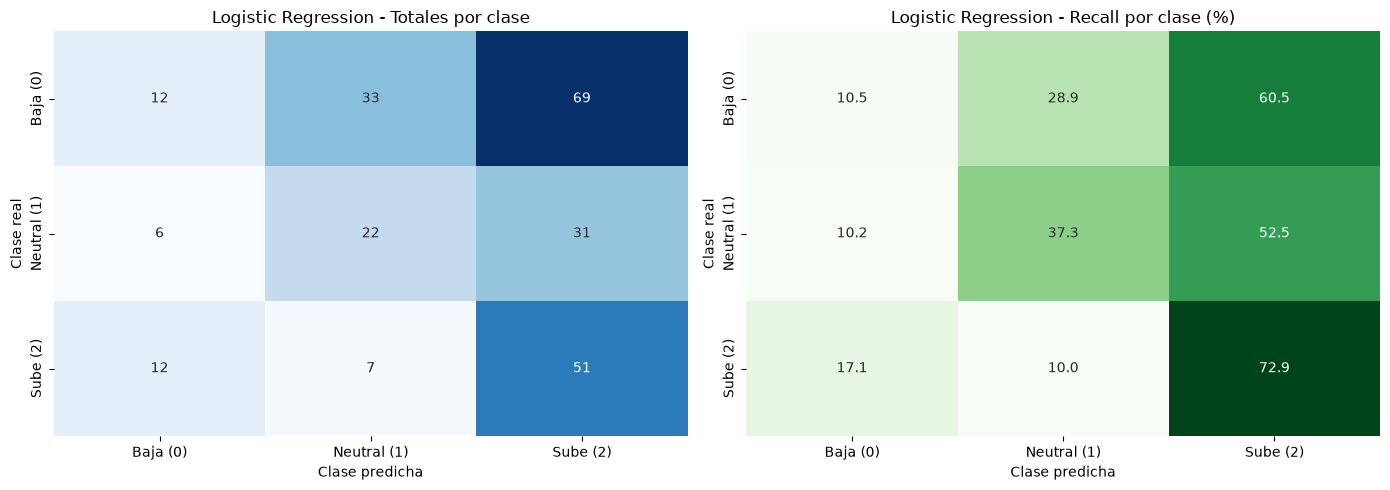



Metricas de clasificación: Random Forest
              precision    recall  f1-score   support

    Baja (0)       0.49      0.34      0.40       114
 Neutral (1)       0.39      0.47      0.43        59
    Sube (2)       0.35      0.46      0.40        70

    accuracy                           0.41       243
   macro avg       0.41      0.42      0.41       243
weighted avg       0.42      0.41      0.41       243



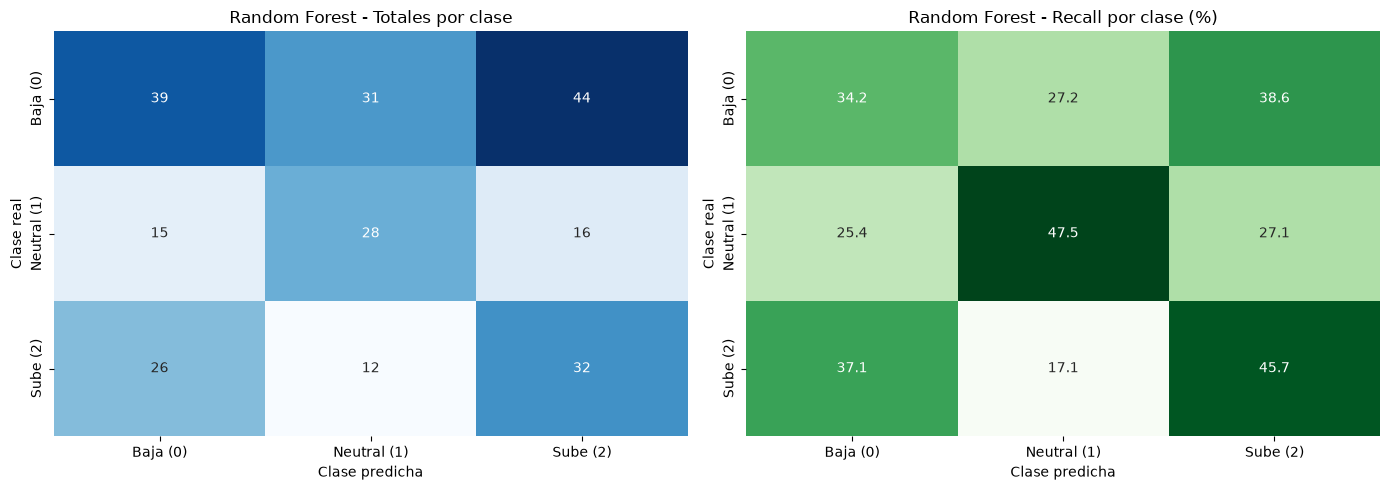



Metricas de clasificación: SVM RBF
              precision    recall  f1-score   support

    Baja (0)       0.45      0.08      0.13       114
 Neutral (1)       0.49      0.36      0.41        59
    Sube (2)       0.32      0.83      0.46        70

    accuracy                           0.36       243
   macro avg       0.42      0.42      0.34       243
weighted avg       0.42      0.36      0.30       243



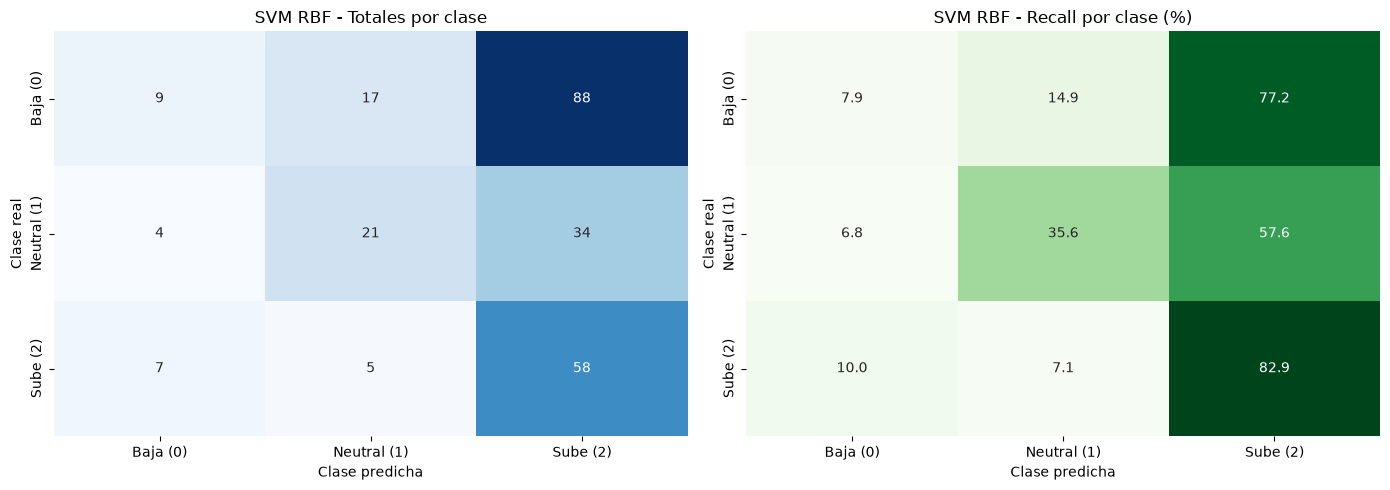



Metricas de clasificación: XGBoost
              precision    recall  f1-score   support

    Baja (0)       0.44      0.50      0.47       114
 Neutral (1)       0.44      0.32      0.37        59
    Sube (2)       0.25      0.26      0.26        70

    accuracy                           0.39       243
   macro avg       0.38      0.36      0.37       243
weighted avg       0.39      0.39      0.38       243



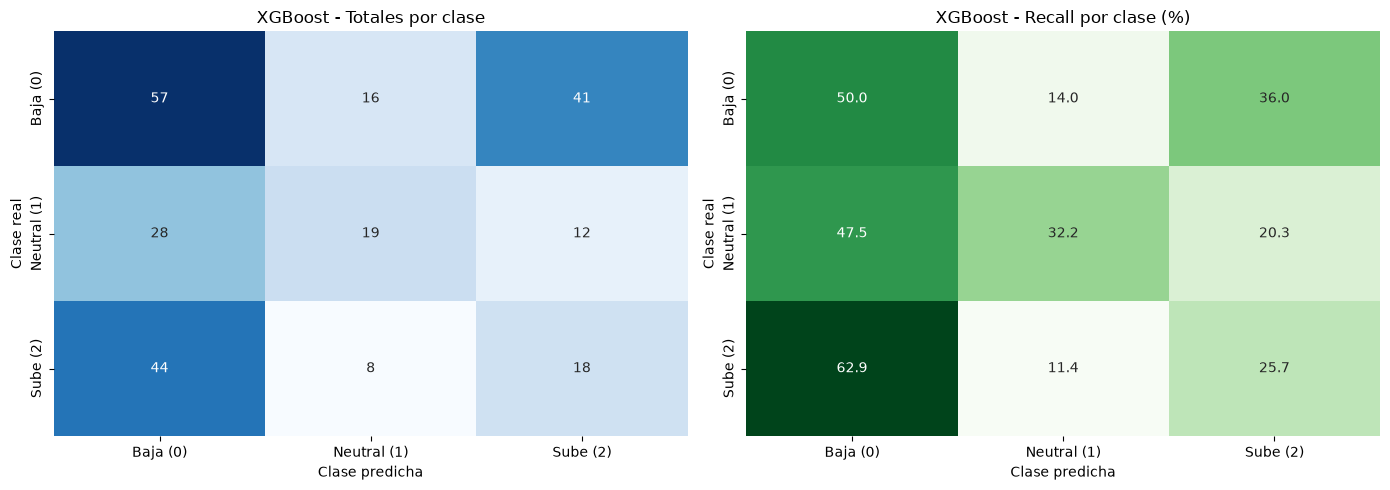



Metricas de clasificación: LightGBM
              precision    recall  f1-score   support

    Baja (0)       0.42      0.52      0.47       114
 Neutral (1)       0.49      0.32      0.39        59
    Sube (2)       0.20      0.19      0.19        70

    accuracy                           0.37       243
   macro avg       0.37      0.34      0.35       243
weighted avg       0.38      0.37      0.37       243



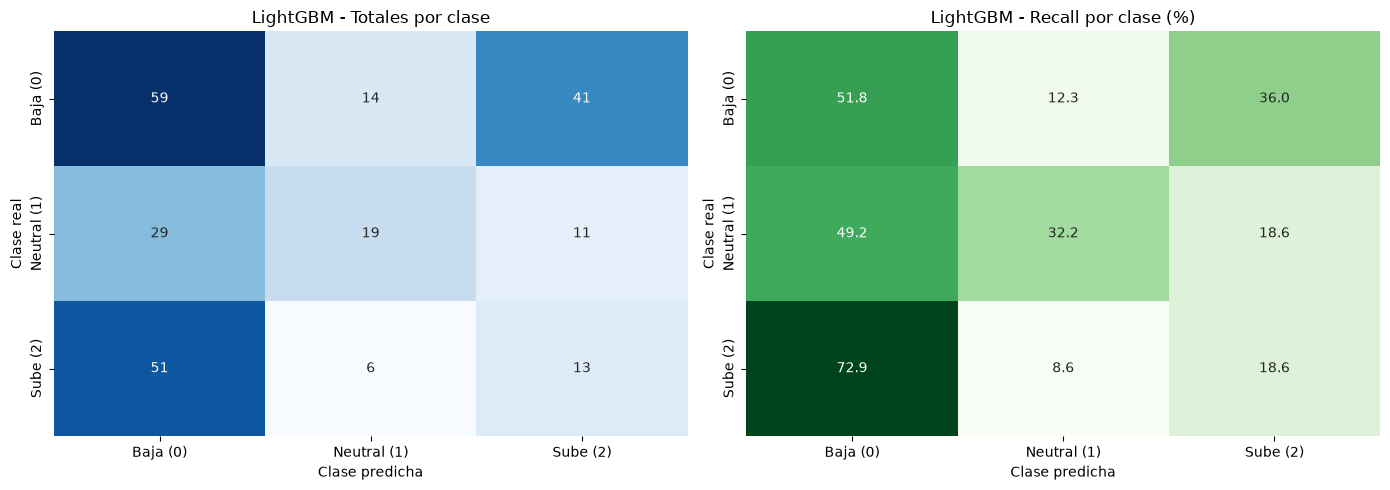

In [775]:
# Matriz de confusión y reporte por modelo de clasificación

nombres_clases = [
    "Baja (0)",
    "Neutral (1)",
    "Sube (2)"
]

for nombre, metricas in resultados.items():

    print("\n")
    print("=" * 45)
    print(
        f"Metricas de clasificación: {nombre}"
    )
    print("=" * 45)

    print(
        classification_report(
            y_test,
            metricas["y_pred"],
            labels=[0, 1, 2],
            target_names=nombres_clases,
            zero_division=0
        )
    )

    matriz = confusion_matrix(
        y_test,
        metricas["y_pred"],
        labels=[0, 1, 2]
    )

    matriz_normalizada = (
        matriz.astype(float)
        / matriz.sum(
            axis=1,
            keepdims=True
        )
    )

    matriz_normalizada = np.nan_to_num(
        matriz_normalizada
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5)
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=nombres_clases,
        yticklabels=nombres_clases,
        ax=axes[0]
    )

    axes[0].set_title(
        f"{nombre} - Totales por clase"
    )

    axes[0].set_xlabel(
        "Clase predicha"
    )

    axes[0].set_ylabel(
        "Clase real"
    )

    sns.heatmap(
        matriz_normalizada * 100,
        annot=True,
        fmt=".1f",
        cmap="Greens",
        cbar=False,
        xticklabels=nombres_clases,
        yticklabels=nombres_clases,
        ax=axes[1]
    )

    axes[1].set_title(
        f"{nombre} - Recall por clase (%)"
    )

    axes[1].set_xlabel(
        "Clase predicha"
    )

    axes[1].set_ylabel(
        "Clase real"
    )

    plt.tight_layout()
    plt.show()


